# Validation, Metrics, and Baselines

**Purpose:** Development validation and baseline comparison for the 2024 CRSS injury-involvement model.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

crashes = pd.read_csv(Path("data/cleaned_crashes.csv")).set_index("CASENUM")
print("Crash rows:", len(crashes))
print("Crash columns:", len(crashes.columns))

Crash rows: 50781
Crash columns: 33


## 1. Reserve the stratified development-test partition

In [2]:
from sklearn.model_selection import train_test_split

SEED = 678
y = crashes["injury_involved"]

development_ids, test_ids = train_test_split(
    crashes.index,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)
development_ids = np.sort(development_ids)
test_ids = np.sort(test_ids)

development = crashes.loc[development_ids].copy()
final_test = crashes.loc[test_ids].copy()

if set(development_ids) & set(test_ids):
    raise ValueError("Development and final-test IDs overlap")

if len(development) + len(final_test) != len(crashes):
    raise ValueError("Development and final-test partitions are not exhaustive")

print("Development rows:", len(development))
print("Reserved test rows:", len(final_test))

Development rows: 40624
Reserved test rows: 10157


## 2. Create five development folds

In [3]:
from sklearn.model_selection import StratifiedKFold

folds = pd.Series(-1, index=development.index, dtype="int8")
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold_number, (_, validation_positions) in enumerate(
    splitter.split(development.index, development["injury_involved"]),
    start=1,
):
    folds.loc[development.index[validation_positions]] = fold_number

if not folds.isin(range(1, 6)).all():
    raise ValueError("Every development crash must receive exactly one fold")

print(folds.value_counts().sort_index())

1    8125
2    8125
3    8125
4    8125
5    8124
Name: count, dtype: int64


## 3. Define context and combined predictors

In [4]:
CONTEXT = [
    "MONTH", "DAY_WEEK", "HOUR", "LGT_COND", "WEATHER",
    "RELJCT2", "TYP_INT", "WRK_ZONE", "VE_FORMS", "PVH_INVL",
]
VEHICLE = [
    "max_posted_mph", "speed_limit_unknown", "speed_limit_special",
    "wet_or_water", "snow_ice_or_slush", "curve", "motorcycle",
    "large_truck", "oldest_model_year", "model_year_unknown",
]
PERSON = [
    "pedestrian", "pedalcyclist", "youngest_driver_age",
    "oldest_driver_age", "driver_age_status", "unknown_occupant_role",
]
COMBINED = CONTEXT + VEHICLE + PERSON

NUMERIC_CONTEXT = ["VE_FORMS", "PVH_INVL"]
CATEGORICAL_CONTEXT = [column for column in CONTEXT if column not in NUMERIC_CONTEXT]
NUMERIC_COMBINED = [
    "VE_FORMS", "PVH_INVL", "max_posted_mph",
    "oldest_model_year", "youngest_driver_age", "oldest_driver_age",
]
CATEGORICAL_COMBINED = [column for column in COMBINED if column not in NUMERIC_COMBINED]

for feature_set in (CONTEXT, COMBINED):
    if len(feature_set) != len(set(feature_set)):
        raise ValueError("A feature set contains duplicate columns")
    forbidden = {
        "CASENUM", "injury_involved", "MAX_SEV", "WEIGHT",
        "PSU", "PSU_VAR", "PSUSTRAT",
    }
    if forbidden.intersection(feature_set):
        raise ValueError("A feature set contains a target or survey-design field")

print("Context predictors:", len(CONTEXT))
print("Combined predictors:", len(COMBINED))

Context predictors: 10
Combined predictors: 26


## 4. Weighted Brier score and no-skill baseline

In [5]:
from sklearn.metrics import brier_score_loss


def weighted_brier(outcome, probability, weights):
    return brier_score_loss(outcome, probability, sample_weight=weights)

baseline_oof = pd.Series(np.nan, index=development.index, dtype="float64")
baseline_fold_results = []

for fold_number in range(1, 6):
    training = development.loc[folds.ne(fold_number)]
    validation = development.loc[folds.eq(fold_number)]
    probability = np.average(training["injury_involved"], weights=training["WEIGHT"])
    baseline_oof.loc[validation.index] = probability
    baseline_fold_results.append({
        "fold": fold_number,
        "weighted_brier": weighted_brier(
            validation["injury_involved"],
            np.full(len(validation), probability),
            validation["WEIGHT"],
        ),
    })

if baseline_oof.isna().any() or not baseline_oof.between(0.0, 1.0).all():
    raise ValueError("No-skill out-of-fold probabilities are incomplete or invalid")

pooled_baseline_brier = weighted_brier(
    development["injury_involved"], baseline_oof, development["WEIGHT"]
)
print(pd.DataFrame(baseline_fold_results))
print("Pooled weighted no-skill Brier:", pooled_baseline_brier)

   fold  weighted_brier
0     1        0.199547
1     2        0.196310
2     3        0.197431
3     4        0.195863
4     5        0.198185
Pooled weighted no-skill Brier: 0.19747262241619337


## 5. Context-only and combined CART baselines

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier


def make_cart_pipeline(features, numeric):
    categorical = [column for column in features if column not in numeric]
    return Pipeline([
        ("prepare", ColumnTransformer([
            ("numeric", SimpleImputer(strategy="median", keep_empty_features=True), numeric),
            ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ])),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=5,
            min_samples_leaf=40,
            ccp_alpha=0.0,
            random_state=SEED,
        )),
    ])


def positive_class_probability(model, features):
    classes = model.named_steps["classifier"].classes_
    if set(classes) != {0, 1}:
        raise ValueError(f"Expected binary classes 0 and 1; received {classes}")
    positive_position = int(np.flatnonzero(classes == 1).item())
    return model.predict_proba(features)[:, positive_position]

cart_oof = pd.Series(np.nan, index=development.index, dtype="float64")
combined_cart_oof = pd.Series(np.nan, index=development.index, dtype="float64")

cart_fold_results = []
combined_cart_fold_results = []

for fold_number in range(1, 6):
    training = development.loc[folds.ne(fold_number)]
    validation = development.loc[folds.eq(fold_number)]
    fold_weights = training["WEIGHT"] / training["WEIGHT"].mean()

    context_model = make_cart_pipeline(CONTEXT, NUMERIC_CONTEXT)
    context_model.fit(
        training[CONTEXT], training["injury_involved"],
        classifier__sample_weight=fold_weights,
    )
    context_probability = positive_class_probability(
        context_model, validation[CONTEXT]
    )
    cart_oof.loc[validation.index] = context_probability
    cart_fold_results.append({
        "fold": fold_number,
        "features": "Context",
        "weighted_brier": weighted_brier(
            validation["injury_involved"],
            context_probability,
            validation["WEIGHT"],
        ),
    })

    combined_model = make_cart_pipeline(COMBINED, NUMERIC_COMBINED)
    combined_model.fit(
        training[COMBINED], training["injury_involved"],
        classifier__sample_weight=fold_weights,
    )
    combined_probability = positive_class_probability(
        combined_model, validation[COMBINED]
    )
    combined_cart_oof.loc[validation.index] = combined_probability
    combined_cart_fold_results.append({
        "fold": fold_number,
        "features": "Combined",
        "weighted_brier": weighted_brier(
            validation["injury_involved"],
            combined_probability,
            validation["WEIGHT"],
        ),
    })

for name, probability in {
    "context CART": cart_oof,
    "combined CART": combined_cart_oof,
}.items():
    if probability.isna().any() or not probability.between(0.0, 1.0).all():
        raise ValueError(f"{name} out-of-fold probabilities are incomplete or invalid")

pooled_cart_brier = weighted_brier(
    development["injury_involved"], cart_oof, development["WEIGHT"]
)
pooled_combined_cart_brier = weighted_brier(
    development["injury_involved"], combined_cart_oof, development["WEIGHT"]
)

print(pd.DataFrame(cart_fold_results))
print(pd.DataFrame(combined_cart_fold_results))
print("Pooled context CART Brier:", pooled_cart_brier)
print("Pooled combined CART Brier:", pooled_combined_cart_brier)

   fold features  weighted_brier
0     1  Context        0.189394
1     2  Context        0.186473
2     3  Context        0.187704
3     4  Context        0.185890
4     5  Context        0.186736
   fold  features  weighted_brier
0     1  Combined        0.177123
1     2  Combined        0.171995
2     3  Combined        0.173322
3     4  Combined        0.173214
4     5  Combined        0.173054
Pooled context CART Brier: 0.1872427384135138
Pooled combined CART Brier: 0.17374494010819552


## 6. Secondary CART metrics

These diagnostics use development out-of-fold probabilities. The `0.50` threshold is a reporting convention, not an operational decision rule.

In [7]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

THRESHOLD = 0.50


def secondary_metrics(outcome, probability, weights, threshold=THRESHOLD):
    prediction = probability >= threshold
    weighted_confusion = confusion_matrix(
        outcome, prediction, labels=[0, 1], sample_weight=weights
    )
    return {
        "weighted_roc_auc": roc_auc_score(
            outcome, probability, sample_weight=weights
        ),
        "weighted_average_precision": average_precision_score(
            outcome, probability, sample_weight=weights
        ),
        "weighted_precision": precision_score(
            outcome, prediction, sample_weight=weights, zero_division=0
        ),
        "weighted_recall": recall_score(
            outcome, prediction, sample_weight=weights, zero_division=0
        ),
        "weighted_f1": f1_score(
            outcome, prediction, sample_weight=weights, zero_division=0
        ),
        "unweighted_brier": brier_score_loss(outcome, probability),
        "weighted_true_negative": weighted_confusion[0, 0],
        "weighted_false_positive": weighted_confusion[0, 1],
        "weighted_false_negative": weighted_confusion[1, 0],
        "weighted_true_positive": weighted_confusion[1, 1],
    }

outcome = development["injury_involved"]
weights = development["WEIGHT"]
cart_secondary = pd.DataFrame([
    {"features": "Context", **secondary_metrics(outcome, cart_oof, weights)},
    {"features": "Combined", **secondary_metrics(outcome, combined_cart_oof, weights)},
])
cart_secondary

,features,weighted_roc_auc,weighted_average_precision,weighted_precision,weighted_recall,weighted_f1,unweighted_brier,weighted_true_negative,weighted_false_positive,weighted_false_negative,weighted_true_positive
0,Context,0.631954,0.396740,0.642838,0.062680,0.114223,0.279280,3.456698e+06,45291.220336,1.219011e+06,81517.381408
1,Combined,0.645473,0.483606,0.858826,0.157783,0.266589,0.228809,3.468258e+06,33730.946001,1.095327e+06,205201.186302


## CART calibration

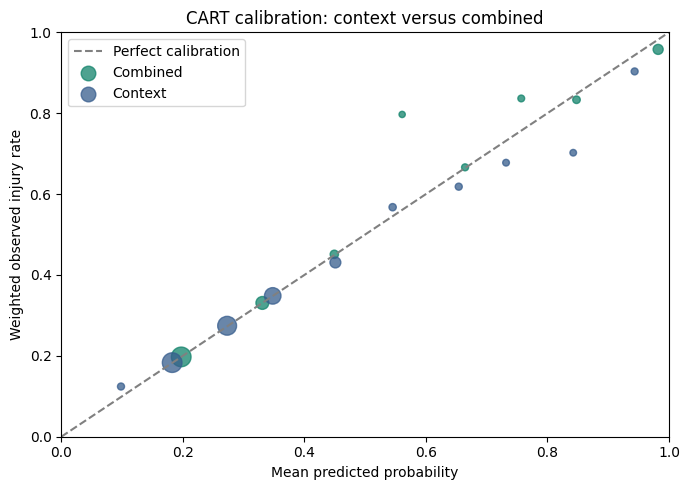

,features,bin,n,weight_sum,effective_n,mean_prediction,observed_injury_rate
0,Context,0,443,7.184647e+04,361.722339,0.098266,0.124148
1,Context,1,13587,1.884072e+06,11093.042922,0.182472,0.183226
2,Context,2,12418,1.417214e+06,8276.598506,0.272906,0.274386
3,Context,3,9152,1.032160e+06,6514.523452,0.347927,0.348298
4,Context,4,3141,2.704165e+05,1888.145794,0.451047,0.430881
5,Context,5,583,4.784076e+04,370.962576,0.545247,0.567574
6,Context,6,446,3.737978e+04,294.368117,0.654016,0.618351
7,Context,7,259,1.672510e+04,149.426041,0.731870,0.677654
8,Context,8,199,1.265031e+04,112.288417,0.842411,0.702272
9,Context,9,396,1.221265e+04,262.136066,0.943452,0.903374


In [8]:
import matplotlib.pyplot as plt


def make_calibration_table(outcome, probability, weights, features):
    frame = pd.DataFrame({
        "outcome": outcome,
        "probability": probability,
        "weight": weights,
    })
    frame["bin"] = np.minimum((frame["probability"] * 10).astype(int), 9)
    rows = []
    for bin_number, group in frame.groupby("bin", sort=True):
        weight_sum = group["weight"].sum()
        rows.append({
            "features": features,
            "bin": bin_number,
            "n": len(group),
            "weight_sum": weight_sum,
            "effective_n": weight_sum ** 2 / group["weight"].pow(2).sum(),
            "mean_prediction": np.average(
                group["probability"], weights=group["weight"]
            ),
            "observed_injury_rate": np.average(
                group["outcome"], weights=group["weight"]
            ),
        })
    return rows

calibration_rows = []
calibration_rows.extend(make_calibration_table(outcome, cart_oof, weights, "Context"))
calibration_rows.extend(
    make_calibration_table(outcome, combined_cart_oof, weights, "Combined")
)
cart_calibration = pd.DataFrame(calibration_rows)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration",
)
colors = {"Context": "#375d8d", "Combined": "#12836b"}

for features, group in cart_calibration.groupby("features"):
    marker_size = 20 + 180 * group["n"] / group["n"].max()
    ax.scatter(
        group["mean_prediction"],
        group["observed_injury_rate"],
        s=marker_size,
        alpha=0.75,
        color=colors[features],
        label=features,
    )

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Weighted observed injury rate")
ax.set_title("CART calibration: context versus combined")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

cart_calibration

## 8. Development candidate search

Compare CART, L2 logistic regression, and random forest across context and combined feature sets. Every model is evaluated only on the existing five development folds; `final_test` is not used.

In [ ]:
import json
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

FEATURE_SETS = {
    "context": CONTEXT,
    "combined": COMBINED,
}

CART_SETTINGS = [
    {"max_depth": depth, "min_samples_leaf": leaf, "ccp_alpha": pruning}
    for depth in [5, 10]
    for leaf in [40, 120]
    for pruning in [0.0, 0.0002]
]
LOGISTIC_SETTINGS = [{"C": c} for c in [0.1, 1.0, 10.0]]
FOREST_SETTINGS = [
    {"n_estimators": 80, "max_depth": 10, "min_samples_leaf": 40},
    {"n_estimators": 120, "max_depth": 18, "min_samples_leaf": 20},
]

print("CART candidates:", len(CART_SETTINGS))
print("Logistic candidates:", len(LOGISTIC_SETTINGS))
print("Random forest candidates:", len(FOREST_SETTINGS))

In [ ]:
def make_candidate(method, features, numeric_features, settings):
    numeric = [column for column in features if column in numeric_features]
    categorical = [column for column in features if column not in numeric]
    numeric_steps = [
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True))
    ]

    if method == "Logistic regression":
        numeric_steps.append(("scale", StandardScaler()))
        classifier = LogisticRegression(
            solver="newton-cholesky",
            max_iter=80,
            tol=1e-7,
            **settings,
        )
    elif method == "CART":
        classifier = DecisionTreeClassifier(
            criterion="gini",
            random_state=SEED,
            **settings,
        )
    elif method == "Random forest":
        classifier = RandomForestClassifier(
            max_features="sqrt",
            random_state=SEED,
            n_jobs=-1,
            **settings,
        )
    else:
        raise ValueError(f"Unknown method: {method}")

    dtype = np.float64 if method == "Logistic regression" else np.float32
    prepare = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
                dtype=dtype,
            ),
            categorical,
        ),
    ])
    return Pipeline([
        ("prepare", prepare),
        ("classifier", classifier),
    ])


def settings_for_method(method):
    if method == "CART":
        return CART_SETTINGS
    if method == "Logistic regression":
        return LOGISTIC_SETTINGS
    if method == "Random forest":
        return FOREST_SETTINGS
    raise ValueError(f"Unknown method: {method}")

In [ ]:
candidate_trials = []
candidate_oof = {}
candidate_fold_scores = []

for method in ["CART", "Logistic regression", "Random forest"]:
    for feature_name, features in FEATURE_SETS.items():
        numeric_features = (
            NUMERIC_CONTEXT if feature_name == "context" else NUMERIC_COMBINED
        )

        for settings in settings_for_method(method):
            oof = pd.Series(np.nan, index=development.index, dtype="float64")

            for fold_number in range(1, 6):
                training = development.loc[folds.ne(fold_number)]
                validation = development.loc[folds.eq(fold_number)]
                normalized_weights = (
                    training["WEIGHT"] / training["WEIGHT"].mean()
                )

                model = make_candidate(
                    method, features, numeric_features, settings
                )
                with warnings.catch_warnings():
                    warnings.simplefilter("error", ConvergenceWarning)
                    model.fit(
                        training[features],
                        training["injury_involved"],
                        classifier__sample_weight=normalized_weights,
                    )

                probability = model.predict_proba(validation[features])[:, 1]
                oof.loc[validation.index] = probability

                candidate_fold_scores.append({
                    "method": method,
                    "features": feature_name,
                    "settings": repr(settings),
                    "fold": fold_number,
                    "n": len(validation),
                    "weighted_brier": weighted_brier(
                        validation["injury_involved"],
                        probability,
                        validation["WEIGHT"],
                    ),
                })

            if not oof.notna().all():
                raise ValueError("Candidate produced incomplete OOF probabilities")

            pooled_brier = weighted_brier(
                development["injury_involved"],
                oof,
                development["WEIGHT"],
            )
            candidate_trials.append({
                "method": method,
                "features": feature_name,
                "settings": repr(settings),
                "pooled_weighted_brier": pooled_brier,
            })
            candidate_oof[f"{method}__{feature_name}__{repr(settings)}"] = oof

candidate_table = pd.DataFrame(candidate_trials).sort_values(
    ["pooled_weighted_brier", "method", "features", "settings"],
    kind="stable",
).reset_index(drop=True)

Path("results").mkdir(parents=True, exist_ok=True)
candidate_table.to_csv(
    "results/development_candidate_scores.csv",
    index=False,
)
pd.DataFrame(candidate_fold_scores).to_csv(
    "results/development_candidate_fold_scores.csv",
    index=False,
)
oof_output = development[["injury_involved", "WEIGHT", "PSU", "PSU_VAR", "PSUSTRAT"]].join(folds)
for label, probability in candidate_oof.items():
    oof_output[label] = probability
oof_output.to_csv(
    "results/development_candidate_oof.csv.gz",
    compression="gzip",
    index_label="CASENUM",
)
print(candidate_table)

## 9. Selected development configurations

The selected configuration for each method and feature set minimizes pooled survey-weighted OOF Brier score.

In [ ]:
selected_rows = (
    candidate_table.sort_values("pooled_weighted_brier")
    .drop_duplicates(["method", "features"])
    .sort_values(["method", "features"])
    .reset_index(drop=True)
)

selected_secondary_rows = []
for row in selected_rows.itertuples(index=False):
    label = f"{row.method}__{row.features}__{row.settings}"
    probability = candidate_oof[label]
    outcome = development["injury_involved"]
    weights = development["WEIGHT"]
    prediction = probability >= THRESHOLD
    weighted_confusion = confusion_matrix(
        outcome,
        prediction,
        labels=[0, 1],
        sample_weight=weights,
    )

    selected_secondary_rows.append({
        "method": row.method,
        "features": row.features,
        "settings": row.settings,
        "pooled_weighted_brier": row.pooled_weighted_brier,
        "weighted_roc_auc": roc_auc_score(outcome, probability, sample_weight=weights),
        "weighted_average_precision": average_precision_score(outcome, probability, sample_weight=weights),
        "weighted_precision": precision_score(outcome, prediction, sample_weight=weights, zero_division=0),
        "weighted_recall": recall_score(outcome, prediction, sample_weight=weights, zero_division=0),
        "weighted_f1": f1_score(outcome, prediction, sample_weight=weights, zero_division=0),
        "unweighted_brier": brier_score_loss(outcome, probability),
        "tn": float(weighted_confusion[0, 0]),
        "fp": float(weighted_confusion[0, 1]),
        "fn": float(weighted_confusion[1, 0]),
        "tp": float(weighted_confusion[1, 1]),
    })

selected_secondary = pd.DataFrame(selected_secondary_rows)
selected_secondary.to_csv(
    "results/development_selected_scores.csv",
    index=False,
)
print(selected_secondary)

## 10. Calibration and fold stability

Selected configurations receive 0.10-wide calibration bins and per-fold weighted-Brier summaries.

In [ ]:
calibration_rows = []
fold_table = pd.DataFrame(candidate_fold_scores)

for row in selected_rows.itertuples(index=False):
    label = f"{row.method}__{row.features}__{row.settings}"
    probability = candidate_oof[label]
    frame = pd.DataFrame({
        "method": row.method,
        "features": row.features,
        "outcome": development["injury_involved"],
        "probability": probability,
        "weight": development["WEIGHT"],
    })
    frame["bin"] = np.minimum((frame["probability"] * 10).astype(int), 9)

    for bin_number, group in frame.groupby("bin", sort=True):
        calibration_rows.append({
            "method": row.method,
            "features": row.features,
            "bin": bin_number,
            "n": len(group),
            "weight_sum": group["weight"].sum(),
            "mean_prediction": np.average(
                group["probability"], weights=group["weight"]
            ),
            "observed_injury_rate": np.average(
                group["outcome"], weights=group["weight"]
            ),
        })

selected_calibration = pd.DataFrame(calibration_rows)
selected_calibration.to_csv(
    "results/development_calibration.csv",
    index=False,
)

selected_fold_labels = set(
    (row.method, row.features, row.settings)
    for row in selected_rows.itertuples(index=False)
)
selected_fold_scores = fold_table[
    fold_table.apply(
        lambda row: (row["method"], row["features"], row["settings"])
        in selected_fold_labels,
        axis=1,
    )
].sort_values(["method", "features", "fold"])
selected_fold_scores.to_csv(
    "results/development_fold_scores.csv",
    index=False,
)

information_comparison = (
    selected_rows
    .pivot(index="method", columns="features", values="pooled_weighted_brier")
    [["context", "combined"]]
)
information_comparison["context_minus_combined"] = (
    information_comparison["context"]
    - information_comparison["combined"]
)

print(selected_calibration)
print(selected_fold_scores)
print(information_comparison)